# Example 2: Si and GaAs recombination and minority diffusion

The lifetimes are declared illustrative controls. The notebook validates a finite-difference minority profile and implicit charge-removal transient.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import elementary_charge as q, Boltzmann as k_B, epsilon_0

ROOT = Path.cwd()
while not (ROOT / "notebooks" / "la2_models.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Could not locate the LA2 workspace")
    ROOT = ROOT.parent
if str(ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "notebooks"))
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
# Direct analytic finite-base solution.
from la2_models import SILICON,GAAS,mobility_m2_Vs,diffusivity_m2_s

T=300.0; doping=1e22; boundary=1e20
controls=[]
for material in (SILICON,GAAS):
    mu=mobility_m2_Vs(material,doping,"hole")
    D=float(diffusivity_m2_s(mu,T))
    tau=material.hole_lifetime_s
    L=np.sqrt(D*tau)
    length=4*L
    x=np.linspace(0,length,301)
    exact=boundary*np.sinh((length-x)/L)/np.sinh(length/L)
    controls.append((material,D,tau,L,length,x,exact))
    print(material.name,f"D={D:.3e} m^2/s, tau={tau:.2e} s, L={L*1e6:.2f} µm")

Si D=1.110e-03 m^2/s, tau=1.00e-05 s, L=105.34 µm
GaAs D=9.351e-04 m^2/s, tau=1.00e-09 s, L=0.97 µm


In [2]:
from la2_models import minority_profile_fd,transient_charge_removal_fd

solutions=[]
for material,D,tau,L,length,x,exact in controls:
    xf,u,flux=minority_profile_fd(length,D,tau,boundary,points=x.size)
    error=np.linalg.norm(u-exact)/np.linalg.norm(exact)
    exact_flux=D*boundary/L/np.tanh(length/L)
    flux_error=abs(flux-exact_flux)/exact_flux
    times=np.linspace(0,6*tau,151)
    xt,history,charge=transient_charge_removal_fd(length,D,tau,boundary,times,points=181)
    assert np.min(history)>=0 and np.all(np.diff(charge)<=1e-20)
    solutions.append((material,xf,u,exact,error,flux_error,times,xt,history,charge))
    print(material.name,f"profile error={error:.3e}; flux error={flux_error:.3e}; Qfinal/Q0={charge[-1]/charge[0]:.3e}")

Si profile error=4.923e-06; flux error=6.640e-03; Qfinal/Q0=5.367e-05
GaAs profile error=4.923e-06; flux error=6.640e-03; Qfinal/Q0=5.367e-05


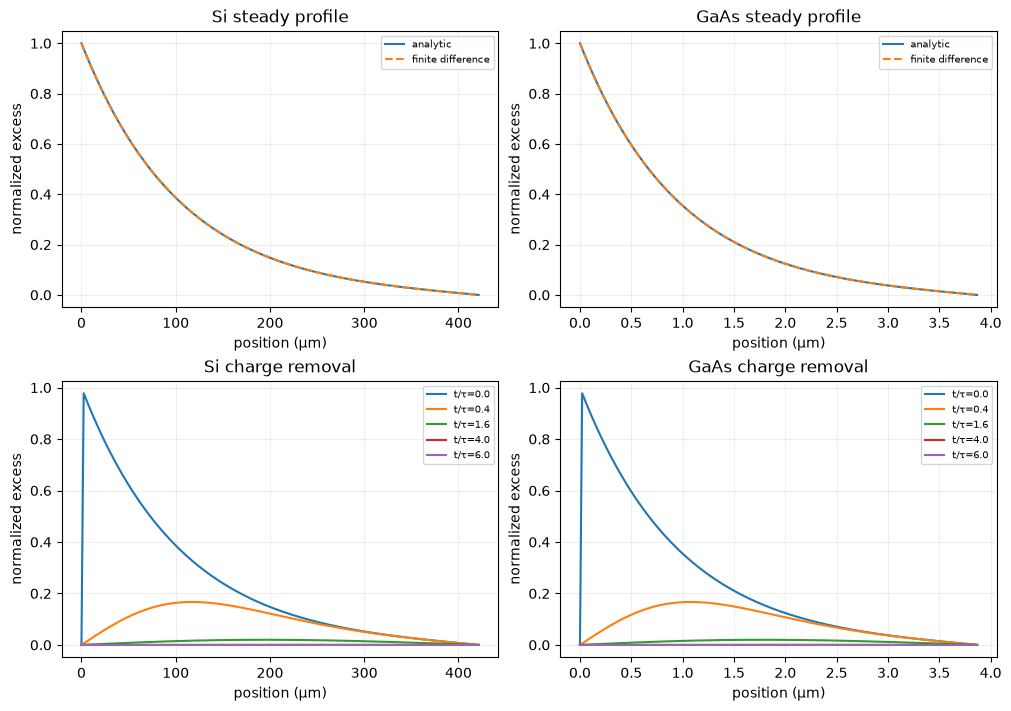

In [3]:
fig,axes=plt.subplots(2,2,figsize=(10,7),layout="constrained")
for column,(material,xf,u,exact,error,flux_error,times,xt,history,charge) in enumerate(solutions):
    axes[0,column].plot(xf*1e6,exact/boundary,label="analytic")
    axes[0,column].plot(xf*1e6,u/boundary,"--",label="finite difference")
    axes[0,column].set(xlabel="position (µm)",ylabel="normalized excess",title=f"{material.name} steady profile")
    for idx in (0,10,40,100,150):
        axes[1,column].plot(xt*1e6,history[idx]/boundary,label=f"t/τ={times[idx]/material.hole_lifetime_s:.1f}")
    axes[1,column].set(xlabel="position (µm)",ylabel="normalized excess",title=f"{material.name} charge removal")
for ax in axes.flat: ax.grid(alpha=.2); ax.legend(fontsize=7)
fig.savefig(FIGURES/'example-si-gaas-recombination.pdf',metadata={'CreationDate':None,'ModDate':None})
plt.show()

In [4]:
# The examples differ mainly because the declared lifetimes differ by four orders of magnitude.
ratio=controls[0][3]/controls[1][3]
print(f"Si/GaAs example diffusion-length ratio = {ratio:.1f}")
print("This ratio is not a universal material constant; it inherits the declared lifetime data.")
print("wrote figures/example-si-gaas-recombination.pdf")

Si/GaAs example diffusion-length ratio = 108.9
This ratio is not a universal material constant; it inherits the declared lifetime data.
wrote figures/example-si-gaas-recombination.pdf
